In [ ]:
# deep learning libraries: torch, neueral network, utils.data
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from torch.nn import functional as F  # use for resizing the image
from pathlib import Path
import matplotlib.pyplot as plt

# random values each time we run the botebook.
torch.manual_seed(42)

# create a folder for save model weights.
# output_folder = Path("module4/output")
# output_folder.mkdir(exist_ok=True)

print("PyTorch version:",torch.__version__)

PyTorch version: 2.14.1+cpu


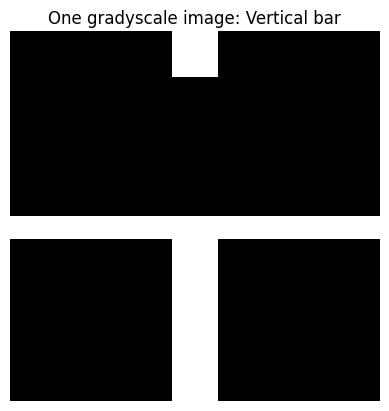

In [ ]:
# create 4 black image: 4 images, 1 channel, 16x16 pixels
image_batch = torch.zeros(4, 1, 16, 16)
# print(f"Frame image:\n{image_batch}")

# make the middle column white to draw a vertical bar if you use 7:9 in thrid position bar will be horizental
image_batch[:, :, :, 7:9] = 1.0
image_batch[:, :, 7:9, :] = 1.0
image_batch[:, :, 2:8, :] = 0.0

# pick 1st the image and its only(grayscale) channel
first_image = image_batch[0,0]

plt.imshow(first_image, cmap="gray", vmin=0, vmax=1)
plt.title("One gradyscale image: Vertical bar")
plt.axis("off")
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

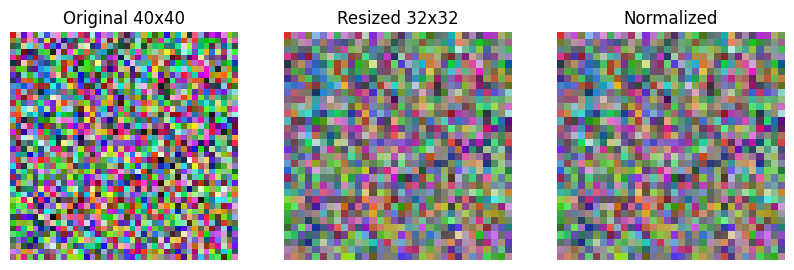

In [ ]:
rgb_batch = torch.rand(1, 3, 40, 40)

# resize the picture from 40x40 to 32x32
resized_32 = F.interpolate(rgb_batch, size=(32, 32), mode="bilinear", align_corners=False)

# move pixel values from [0, 1] to [-1, 1]
normalized = (resized_32 - 0.5) / 0.5
display_normalized = normalized * 0.5 + 0.5

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
example = [rgb_batch, resized_32, display_normalized]
titles = ["Original 40x40", "Resized 32x32", "Normalized"]
for i in range(3):
  picture = example[i][0].permute(1, 2, 0)
  axes[i].imshow(picture)
  axes[i].set_title(titles[i])
  axes[i].axis("off")
plt.show

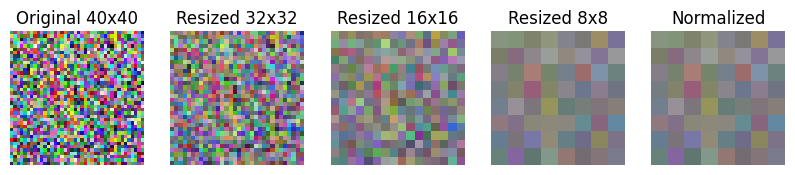

In [ ]:
rgb_batch = torch.rand(1, 3, 40, 40)

# resize the picture from 40x40 to 32x32
resized_32 = F.interpolate(rgb_batch, size=(32, 32), mode="bilinear", align_corners=False)
resized_16 = F.interpolate(resized_32, size=(16, 16), mode="bilinear", align_corners=False)
resized_8 = F.interpolate(resized_16, size=(8, 8), mode="bilinear", align_corners=False)

# move pixel values from [0, 1] to [-1, 1]
normalized = (resized_8 - 0.5) / 0.5
display_normalized = normalized * 0.5 + 0.5


fig, axes = plt.subplots(1, 5, figsize=(10, 3))
example = [rgb_batch, resized_32, resized_16, resized_8, display_normalized]
titles = ["Original 40x40", "Resized 32x32", "Resized 16x16", "Resized 8x8", "Normalized"]
for i in range(5):
  picture = example[i][0].permute(1, 2, 0)
  axes[i].imshow(picture)
  axes[i].set_title(titles[i])
  axes[i].axis("off")
plt.show()

In [ ]:
# check the set of values
print(rgb_batch)

tensor([[[[0.1947, 0.7839, 0.3582,  ..., 0.9632, 0.3246, 0.0225],
          [0.9664, 0.2312, 0.9781,  ..., 0.9079, 0.4611, 0.3369],
          [0.7501, 0.2579, 0.6764,  ..., 0.0711, 0.8554, 0.2914],
          ...,
          [0.0049, 0.4389, 0.7163,  ..., 0.0205, 0.8501, 0.9850],
          [0.6434, 0.3044, 0.6098,  ..., 0.5810, 0.3944, 0.2275],
          [0.2706, 0.2962, 0.0320,  ..., 0.3110, 0.5391, 0.8760]],

         [[0.6630, 0.1910, 0.8019,  ..., 0.1636, 0.4947, 0.0946],
          [0.8229, 0.9774, 0.3089,  ..., 0.4791, 0.5609, 0.1724],
          [0.4384, 0.9895, 0.8097,  ..., 0.7890, 0.2927, 0.7978],
          ...,
          [0.8644, 0.0860, 0.8789,  ..., 0.7067, 0.0843, 0.5210],
          [0.9312, 0.4798, 0.5811,  ..., 0.8582, 0.0870, 0.0869],
          [0.0851, 0.8142, 0.2461,  ..., 0.5072, 0.3100, 0.3601]],

         [[0.4309, 0.3986, 0.1907,  ..., 0.2605, 0.8784, 0.4511],
          [0.2938, 0.9149, 0.5761,  ..., 0.9890, 0.9186, 0.8131],
          [0.7220, 0.3029, 0.0965,  ..., 0

Image torch.Size([240, 1, 16, 16])
Label torch.Size([240])


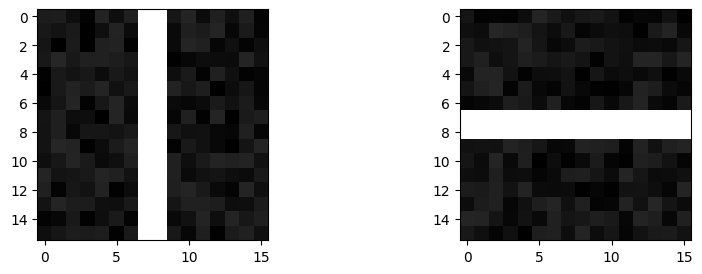

In [ ]:
def make_patterns(seed=42, noise=0.15):
  generator = torch.Generator().manual_seed(seed)
  # 240 labels: 0=vertical, 1=horizontal
  labels = torch.arange(240) % 2
  # start with black 240, 16x16 grayscale pictures
  pictures = torch.zeros(240, 1, 16, 16)
  # draw white vertical bar for class 0
  pictures[labels == 0, :, :, 7:9] = 1.0
  # draw white vertical bar for class 1
  pictures[labels == 1, :, 7:9, :] = 1.0
  # add noise
  random_noise = torch.rand(pictures.shape, generator=generator)
  pictures += noise * random_noise
  # shuffle theimage and labels in the same order.
  order = torch.randperm(240, generator=generator)
  return pictures[order], labels[order]
images, image_labels = make_patterns(seed=42, noise=0.15)
print("Image", images.shape)
print("Label", image_labels.shape)

# display the images
fig, axes = plt.subplots(1,2, figsize=(10, 3))
example = [images[0], images[1]]
titles = ["Vertical bar", "Horizontal bar"]
for i in range(2):
  axes[i].imshow(example[i][0], cmap="gray", vmin=0, vmax=1)


In [ ]:
# our first training Dataset

# keep 180 images for sourcce training
train_images_souce = images[:180]
# flip them left to right. dimension 3 is the image width.
flipped_images = torch.flip(train_images_souce, dims=[3])
# flipped the image to original training images.
augmented_images = torch.cat([train_images_souce, flipped_images])
# flipped image keep the same class label.
augmented_labels = torch.cat([image_labels[:180], image_labels[:180]])

print(f"Original images:     {len(train_images_souce)}")
print(f"Augmented images:    {len(augmented_images)}")
print(f"Unseen souce images: {len(flipped_images[180:])}")

Original images:     180
Augmented images:    360
Unseen souce images: 0


### Conv2d -> ReLU -> MaxPooL2d => Flatten


#### Create 8 filter taht each look at a 3x3 area

In [ ]:

# 1. Input channel = one grayscale image channel
conv = nn.Conv2d(1, 8, kernel_size=3, padding=1)
# send 4 images through filter
feature_maps = conv(images[:4])
# change negative values to zero using activation function.
activated = torch.relu(feature_maps)
# MaxPool keeps the large value in each 2x2 area(window).
# Image size changes from 16x16 to 8x8
pooled = nn.MaxPool2d(2)(activated)
# turn the 8 feature maps into 3 times 8 = 512 numbers per image.
flat = nn.Flatten()(pooled)
print(f"After Conv2d: {feature_maps.shape}")
print(f"After ReLU: {activated.shape}")
print(f"After MaxPool2d: {pooled.shape}")
print(f"After Flatten: {flat.shape}")

After Conv2d: torch.Size([4, 8, 16, 16])
After ReLU: torch.Size([4, 8, 16, 16])
After MaxPool2d: torch.Size([4, 8, 8, 8])
After Flatten: torch.Size([4, 512])


In [ ]:
def build_cnn():
  # build a new cnn. the five layers run from the top to bottom.
  return nn.Sequential(
    nn.Conv2d(1, 8, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(512, 2)
    )

cnn = build_cnn()
scores = cnn(images[:4])

print(cnn)
print(f"Scores: {scores.shape}")

Sequential(
  (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Flatten(start_dim=1, end_dim=-1)
  (4): Linear(in_features=512, out_features=2, bias=True)
)
Scores: torch.Size([4, 2])


In [ ]:
# pair each image with its correct lebal.
source_data = TensorDataset(augmented_images, augmented_labels)
# make batches of 30 images; shuffle before each epoch.
source_loader = DataLoader(source_data, batch_size=30, shuffle=True)
# Create the cnn that we want to train
source_model = build_cnn()
# Loss measures wrong predictions; adam updates the weights.
loss_fn = nn.CrossEntropyLoss()
source_optimizer = torch.optim.Adam(source_model.parameters(), lr=0.01)
# repeat training for 5 epochs (5 pases throuhg the dataset).
for epoch in range(5):
  source_model.train()
  total_loss = 0.0
  # take on batch of images and labels at a time.
  for batch_images, batch_labels in source_loader:
    source_optimizer.zero_grad()
    scores = source_model(batch_images)
    loss = loss_fn(scores, batch_labels)
    loss.backward()
    source_optimizer.step()
    total_loss += loss.item()
  # print average loss over the whole training dataset.
  average_loss = total_loss / len(source_loader)
  print(f"Epoch {epoch + 1} loss: {average_loss:.4f}")
# save the trained weights os we cacn reuse
# torch.save(source_model.state_dict(), "module4/output/source_model.pth")
print("Saved Trained CNN weights")

Epoch 1 loss: 0.1761
Epoch 2 loss: 0.0001
Epoch 3 loss: 0.0000
Epoch 4 loss: 0.0000
Epoch 5 loss: 0.0000
Saved Trained CNN weights


In [ ]:
source_model.eval()
with torch.inference_mode():
  test_scores = source_model(images[180:])
  predictions = test_scores(1).argmax(dim=1)
  pass

### Transformer

In [ ]:
from numpy import unique_all
# use six word (four of them are different)
words = ["we", "are", "study", "python", "we", "study", "pytorch"]
unique_words = sorted(set(words))
vocabulary = {}
for i, w in enumerate(unique_words):
  vocabulary[w] = i
first_ids = []
for word in words[:3]:
  first_ids.append(vocabulary[word])
print(vocabulary)
print(first_ids)
token_ids = torch.tensor(first_ids)
print(token_ids)
embedding = nn.Embedding(num_embeddings=len(vocabulary), embedding_dim=2)
embedding(token_ids)
word_vector = embedding(token_ids)
print("-"*40)
print(f"Vocabulary: {vocabulary}")
print(f"Token IDs: {token_ids}")
print(f"Word Vectors: {word_vector.shape}")

{'are': 0, 'python': 1, 'pytorch': 2, 'study': 3, 'we': 4}
[4, 0, 3]
tensor([4, 0, 3])
----------------------------------------
Vocabulary: {'are': 0, 'python': 1, 'pytorch': 2, 'study': 3, 'we': 4}
Token IDs: tensor([4, 0, 3])
Word Vectors: torch.Size([3, 2])
Word vectors: tensor([[ 0.3073,  0.6517],
        [ 0.2028,  0.1379],
        [ 0.2883, -0.2570]], grad_fn=<EmbeddingBackward0>)
